# Sorting regulatory PDFs by document type

## A folder of public records

Suppose a company is about to buy an old paper mill. Before the sale closes, an environmental consultant downloads the public record on the site from the US Environmental Protection Agency (EPA) and the state regulators. It arrives as a folder of 80 PDFs with names like `viewdoc.aspx` and `ar-096.pdf`. Somewhere in it are the mill's discharge permits, letters from the regulators, inspection reports, a court settlement over past violations and notices of public hearings.

The consultant's first job is not to read every page but to sort the folder. A settlement or an enforcement order tells the buyer about penalties and clean-up duties that may pass to the new owner, so it is read first and in full. A notice announcing a hearing can wait.

A useful sorting step files each PDF under the right type and says which ones it is unsure about, so that a person can look at those. Each mistake has a cost. A settlement filed as an ordinary letter may never be read, and the buyer takes on a penalty nobody mentioned. The same sorting step is needed wherever documents arrive in bulk from regulators: a car maker's recall notices, a nursing home's inspection forms, the dozens of filings in a utility's rate case.

### An illustrative example

This example is made up, to show the task. The folder holds two PDFs.

The first opens with a page headed "Final permit". It names the mill, the river it discharges into and the limits on what it may release. Anyone reading that page knows what the document is. This is the ordinary case: the first page says what the document is.

The second opens with a one-page letter from the agency: "Please find enclosed the accepted label for your product. Changes in labeling must be submitted before release." Pages 2 to 15 are the product label itself: the active ingredient, the directions for use, first aid, storage and disposal. If you read only the first page, you file this PDF as correspondence. If you turn the page, you see that the letter is a cover sheet and the document is a pesticide label.

A careful person handles the second file by flipping through it before deciding, and by asking what the document as a whole is for. A program that sorts documents has to make the same choice explicitly: how much of each document to read. Reading more costs more and takes longer, and for most documents the first page is enough. For documents that open with a cover letter, the first page points the wrong way.

### What a document's type means

The two files hold a second trap. A permit and the fact sheet that explains it discuss the same river, the same pollutants and the same mill. A letter that sends out a permit mentions the permit on every line. What separates them is not the subject but the purpose and the form: a permit grants permission and sets conditions, a fact sheet explains the reasons for those conditions, and a letter sends or asks for something. A method that matches documents by subject sees these as nearly the same document. A method that sorts by type has to look at what the document does.

### Asking a decision model

This experiment does the sorting with a decision model. A decision model is a language model offered for one narrow job: it receives some evidence (here, the text of a document) and a question with a fixed list of possible answers, and it returns a probability for each answer instead of writing text. Asked "What type of document is this?" with a list such as "final discharge permit, permit fact sheet, regulatory letter, pesticide label", it might return 0.94 for pesticide label, 0.04 for regulatory letter and almost nothing for the rest.

Two things make this shape suit a sorting job. The answer is always one of the listed types, so nothing has to be pulled out of free text. And the probability suggests a rule for the person in the loop: accept the answer when it is high, and send the document to a person when it is low. That rule works only if a high probability really means the answer is likely right, which is something to test rather than assume.

### Three ways to ask, and how much to read

The study sorts documents into 101 types, arranged in 13 groups such as "water permitting", "environmental enforcement" and "utility rate-case filings". There are three reasonable ways to put that many types to a decision model:

- Ask one question with all 101 types as the answers. The model sees every option, including the near neighbours it has to rule out, such as the permit and its fact sheet. It is the simplest design, but every request carries the descriptions of all 101 types.
- Ask in two steps: first which of the 13 groups the document belongs to, then which type within the two most likely groups. Each question is shorter, but a wrong group at the first step can rule out the right type.
- Make a shortlist first, without a language model. An embedding model turns a text into a list of numbers so that texts on similar subjects get similar numbers. It compares the document with each type's description and keeps the 15 closest, and the decision model chooses among those. Each request is about half as long, but a type the shortlist left out cannot be chosen, and the shortlist is built from subject similarity.

The similarity comparison on its own, picking the single closest type with no decision model, is the cheapest baseline. Across the designs there is also the choice from the example: whether the model reads about one page of text (the first 2,000 characters) or about two to four pages (the first 8,000).

## The question

When a public regulatory PDF has to be filed as one of 101 document types, which way of asking a decision model gets the type right most often for its cost: one question over all 101 types, a group first and then a type, or a 15-type shortlist made by subject similarity? And does the model need about a page of text, or does it do better with four times as much? The test uses 276 PDFs from 22 collections published by US and UK regulators and agencies.

A team building a sorting step needs both answers. The design sets the cost per document and decides which mistakes are possible, and the amount of text decides whether documents that open with a cover letter can be sorted at all.

## Study summary

The decision model was OpenAI's Decisions API, which runs GPT-6 Luna. The three designs that use it share one instruction, to judge "the document's form and purpose, not just its topic". The model sorted 276 public PDFs, from permits and inspection forms to recall notices, accident reports and rate-case filings, each with a known correct type. Of the 101 types, 78 occur in these documents; the other 23 are plausible neighbours the model has to rule out. The main measure is accuracy, the share of documents whose most probable type is the correct one.

- One question over all 101 types, reading 8,000 characters, got 251 of 276 documents right (90.9%), and the correct type was among its three most probable answers for 265 (96.0%). It cost $0.47 per 1,000 documents. Asking for the group first also got 251 right. The two designs disagreed on only 6 documents, 3 each way, so this test cannot separate them.
- The 15-type shortlist got 243 right (88.0%) at $0.22 per 1,000 documents. For 19 documents the correct type was not on the shortlist, so the decision model could not choose it. One request was refused by the service; on the 275 readable replies the shortlist got 243 right (88.4%), and the order of the designs does not change. The similarity comparison alone got 179 right (64.9%).
- Reading 8,000 characters instead of 2,000 raised the one-question design from 240 to 251 right. It fixed 11 documents and broke none. Five of the 11 were EPA pesticide labels, which open with EPA's registration notice: none of the 8 labels was right on 2,000 characters, and 5 were on 8,000.
- The probabilities do not flag most mistakes. 17 of the 25 wrong answers from one question on 8,000 characters came with a probability of 0.9 or more, and 214 of its 276 answers came back at exactly 1.00, 7 of them wrong.

In the consultant's folder, a decision model given about four pages of each PDF and all 101 types would file about nine documents in ten correctly, for less than half a dollar per thousand documents. A probability threshold would not find most of its mistakes. Documents that open with a letter, and close neighbours such as a rate-case motion and a letter, still need a person to check them.

The caveat that most affects this answer is size. The 276 documents cover 78 types, and 64 of those types have between one and four documents, so results for any single type rest on very few examples. Most of the documents were also public before the model's training cutoff (236 of 276 carry an earlier date in the catalog), so the model may have seen some of them, and the accuracy is an upper bound for new documents.

## Contents

1. [Setup](#1.-Setup)
2. [Data](#2.-Data)
3. [Method](#3.-Method)
4. [Results](#4.-Results)
5. [Error analysis](#5.-Error-analysis)
6. [Cost of the run](#6.-Cost-of-the-run)
7. [What the evidence supports](#7.-What-the-evidence-supports)
8. [Limitations](#8.-Limitations)
9. [How to reproduce](#9.-How-to-reproduce)
10. [Future work and further reading](#10.-Future-work-and-further-reading)

## How the experiment runs

Each document's text is extracted once. The decision model then answers under four set-ups (one question on 2,000 and on 8,000 characters, group first, shortlist first), and the similarity comparison runs without it. Every reply is cached in `data/decisions_cache_classification.jsonl`, keyed by the full request, so running the notebook again reads the replies from disk. One document travels through it like this: a pesticide label is downloaded and checked against its fingerprint, its first six pages become text, and that text is sent to the decision model once per design; section 3.2 follows it step by step.

```mermaid
flowchart TD
    tax["Type list written for this notebook<br/>101 types in 13 groups<br/>20 distractors never in the corpus"]
    cat["data/catalog: public PDFs pinned by web address and sha256<br/>22 collections, files up to 3 MB"]
    gold["Correct types<br/>rules from publisher metadata: 21 collections, 194 documents<br/>first page read by hand: facility records, 82 documents"]
    dl["Download, check sha256, extract text (PyMuPDF)<br/>first 6 pages, up to 8,000 characters<br/>289 selected, 13 dropped for no text, 276 kept"]
    emb["Embedding model (OpenRouter, free)<br/>101 type vectors + 276 document vectors"]
    A["Similarity only<br/>closest type, no decision call"]
    B["One question over 101 types<br/>276 calls on 2,000 characters + 276 on 8,000<br/>22 requests identical: text of 2,000 characters or fewer"]
    C["Group first<br/>2 calls per document, 552 calls"]
    D["Shortlist first<br/>15 closest types, 1 call per document<br/>275 answered, 1 refused"]
    score["Score 5 runs x 276 documents<br/>accuracy, top-3, macro-F1, group accuracy,<br/>cost per 1,000 documents, probability thresholds"]
    res["1,379 calls, 1,357 distinct requests, $0.41"]
    tax --> gold
    cat --> gold --> dl
    tax --> emb
    dl --> emb
    emb --> A
    emb --> D
    dl --> B
    dl --> C
    tax --> B
    tax --> C
    A --> score
    B --> score
    C --> score
    D --> score
    score --> res
```

## 1. Setup

The next cell sets the configuration that every later step uses: the decision model (`openai/gpt-6-luna-decisions`) and the embedding model (`nvidia/llama-nemotron-embed-vl-1b-v2:free`), both reached through OpenRouter; the two excerpt lengths, 2,000 and 8,000 characters; a random seed of 7 for sampling documents; and eight parallel workers.

The catalog in `data/catalog/` lists one public PDF per row with its web address, size and sha256 fingerprint. On the first run the PDFs are downloaded into `data/docs/` (git-ignored, about 300 MB) and checked against the fingerprint, and a file whose bytes changed upstream is dropped rather than used. Every model reply is cached in `data/`, so a re-run replays from disk and needs no key. `OPENROUTER_API_KEY` is needed only for a request that is not in the cache. The free embedding endpoint may log its inputs, which is acceptable only for public documents. The Decisions endpoint has no free version, and its spend is printed in section 6.

In [1]:
import hashlib, json, os, random, re, shutil, threading, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
import requests
from sklearn.metrics import f1_score

ROOT = Path.cwd()  # this notebook's folder
DATA = ROOT / "data"
CAT, DOCS = DATA / "catalog", DATA / "docs"

DECISIONS_URL = "https://openrouter.ai/api/alpha/decisions"
EMBED_URL = "https://openrouter.ai/api/v1/embeddings"
DECISIONS_MODEL = "openai/gpt-6-luna-decisions"
EMBED_MODEL = "nvidia/llama-nemotron-embed-vl-1b-v2:free"  # free
SHORT, LONG = 2_000, 8_000  # excerpt lengths (characters from the start of the document)
SEED, WORKERS = 7, 8

HEADERS = {"Authorization": f"Bearer {os.environ.get('OPENROUTER_API_KEY', '')}"}  # only used on a cache miss
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

### 1.1 Helpers

The next cell defines the tools the later steps share.

- `post()` sends a request to OpenRouter and retries on rate limits and server errors. It treats HTTP 502 with "refused" in the message as a refusal and does not retry it.
- `JsonlCache` stores every reply in `data/decisions_cache_classification.jsonl`, keyed by a hash of the full request (model, document text and question). The same request is never paid for twice, and a re-run needs no network.
- `decide()` makes one Decisions call, and `embed()` returns embedding vectors, cached in `data/embeddings_cache.npz`.
- `pmap()` runs eight documents at a time and turns a refusal into the answer `<refused>`, which is scored as wrong and also counted in its own column.

The cache stores each reply but not the request text, so linking a reply back to its document needs the extracted text from section 2.4.

In [2]:
class Refused(Exception):
    """The model declined to answer (HTTP 502 'refused to answer'); not worth retrying."""


def post(url, payload, tries=8):
    if not os.environ.get("OPENROUTER_API_KEY"):
        raise RuntimeError(f"Not in the cache and OPENROUTER_API_KEY is not set ({url})")
    for attempt in range(tries):
        r = requests.post(url, json=payload, headers=HEADERS, timeout=180)
        if r.status_code == 200:
            return r.json()
        if r.status_code == 502 and "refused" in r.text:
            raise Refused(r.text[:200])
        if r.status_code in (429, 500, 502, 503, 504) and attempt < tries - 1:
            time.sleep(min(60, 5 * 2**attempt) if r.status_code == 429 else 2**attempt)  # free models rate-limit harder
            continue
        raise RuntimeError(f"HTTP {r.status_code}: {r.text[:400]}")


class JsonlCache:
    """Append-only on-disk cache for API responses, keyed by the request payload."""

    def __init__(self, path):
        self.path, self.lock, self.data = path, threading.Lock(), {}
        if path.exists():
            for line in path.read_text(encoding="utf-8").splitlines():
                row = json.loads(line)
                self.data[row["key"]] = row["value"]

    def get(self, payload, fn):
        key = hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()
        if key not in self.data:
            value = fn(payload)
            with self.lock:
                self.data[key] = value
                with self.path.open("a", encoding="utf-8") as f:
                    f.write(json.dumps({"key": key, "value": value}) + "\n")
        return self.data[key]


DATA.mkdir(parents=True, exist_ok=True)
decision_cache = JsonlCache(DATA / "decisions_cache_classification.jsonl")


def decide(state, questions):
    def call(payload):
        t0 = time.perf_counter()
        try:
            out = post(DECISIONS_URL, payload)
        except Refused as e:
            return {"refused": str(e)}
        return {"answers": out["answers"], "usage": out["usage"], "latency_s": time.perf_counter() - t0}

    result = decision_cache.get({"model": DECISIONS_MODEL, "state": state, "questions": questions}, call)
    if "refused" in result:
        raise Refused(result["refused"])
    return result


EMB_PATH = DATA / "embeddings_cache.npz"
if EMB_PATH.exists():
    with np.load(EMB_PATH) as z:  # plain arrays, no pickle
        emb_cache = dict(zip(z["keys"].tolist(), z["vectors"]))
else:
    emb_cache = {}


def save_emb_cache():
    keys = list(emb_cache)
    np.savez(EMB_PATH, keys=np.array(keys), vectors=np.stack([emb_cache[k] for k in keys]).astype(np.float32))


def embed(texts, batch=256):
    key = lambda t: hashlib.sha1(f"{EMBED_MODEL}|{t}".encode()).hexdigest()
    missing = list(dict.fromkeys(t for t in texts if key(t) not in emb_cache))
    for i in range(0, len(missing), batch):
        part = missing[i : i + batch]
        inputs = [t if t.strip() else "(blank)" for t in part]  # the free model rejects empty strings
        out = post(EMBED_URL, {"model": EMBED_MODEL, "input": inputs, "dimensions": 512, "encoding_format": "float"})
        for t, d in zip(part, sorted(out["data"], key=lambda d: d["index"])):
            emb_cache[key(t)] = np.asarray(d["embedding"], dtype=np.float32)
    if missing:
        save_emb_cache()
    X = np.stack([emb_cache[key(t)] for t in texts])
    return X / np.linalg.norm(X, axis=1, keepdims=True)


def pmap(fn, items):
    def safe(x):
        try:
            return fn(x)
        except Refused:
            return {"top": ["<refused>"], "conf": 0.0, "calls": [], "refused": True}

    with ThreadPoolExecutor(WORKERS) as ex:
        return list(ex.map(safe, items))

## 2. Data

### 2.1 The 101 types

The type list was written for this notebook. Each type has a one-sentence description, and that description is the text the decision model sees for each answer. The descriptions are general definitions, not phrases copied from the documents. Twenty types are distractors: realistic types that never occur in the corpus, added so that the model has to rule them out. Three more types have no scored document: all four corrective-measures work plans were scans and were dropped, and the sample holds no document of the other two. The groups range from 3 types (corporate and nonprofit reporting) to 15 (hazardous waste and site clean-up).

A few rows show how close the neighbours are:

| Type | Description given to the model | In the scored set |
|---|---|---|
| Wastewater discharge permit (final) | Issued NPDES or state-equivalent permit or adopted waste discharge requirements order authorizing discharges to surface water, with effluent limits and monitoring requirements. | 25 documents |
| Permit fact sheet | Explanatory fact sheet accompanying a draft discharge permit: facility description, receiving water and the basis for each limit. | 1 document |
| Discharge monitoring report (DMR) | Periodic permittee form reporting measured effluent values against permit limits for each outfall and parameter. | Distractor |
| Regulatory correspondence letter | Letter between regulator and facility transmitting a permit, approving a request, or requiring information or action. | 4 documents |
| Pesticide product label | Registered pesticide product label: ingredients, directions for use, precautionary statements and storage/disposal. | 8 documents |

(NPDES is the US federal discharge permit program.) The next cell defines all 101 types with their descriptions and groups. Types marked † are the distractors. What to look for: the printed count of types, groups and distractors, and the number of types in each group.

In [3]:
TAXONOMY = {
    "Water permitting & drinking water": {
        "Wastewater discharge permit (final)": "Issued NPDES or state-equivalent permit or adopted waste discharge requirements order authorizing discharges to surface water, with effluent limits and monitoring requirements.",
        "Draft or tentative discharge permit": "Draft, proposed or tentative discharge permit or order released for public comment before final issuance.",
        "Discharge permit modification": "Document formally modifying the conditions of an existing discharge permit (major or minor modification).",
        "Permit fact sheet": "Explanatory fact sheet accompanying a draft discharge permit: facility description, receiving water and the basis for each limit.",
        "Drinking water consumer confidence report": "Annual water quality report from a public water system to its customers listing detected contaminants against regulatory limits.",
        "Discharge monitoring report (DMR) †": "Periodic permittee form reporting measured effluent values against permit limits for each outfall and parameter.",
        "Stormwater pollution prevention plan (SWPPP) †": "Facility plan describing stormwater sources and the best management practices that control pollutants in runoff.",
    },
    "Air permitting & air quality": {
        "Air operating permit": "Issued Title V / Part 70, state or district operating permit (or temporary permit) with emission limits, monitoring and recordkeeping for air emission sources.",
        "Air construction / new source review permit or order": "Pre-construction or new source review air license, amendment or departmental order with findings of fact.",
        "Air permit evaluation or statement of basis": "Regulator's engineering evaluation, application review or statement of basis explaining an air permit action.",
        "Permittee air compliance monitoring report": "Semi-annual or annual report from a permittee to an air agency on monitoring results, deviations and compliance certification.",
        "Flare event causal analysis report": "Refinery report to an air district analysing a flaring event: duration, volumes, root cause and prevention measures.",
        "Air quality designation / technical support document": "Agency technical analysis supporting air-quality area designations or rulemaking (attainment / nonattainment).",
        "Petition to object to a Title V permit": "Petition asking the EPA Administrator to object to a Title V operating permit issued by a state or local agency.",
        "Greenhouse gas emissions report †": "Facility or corporate report quantifying greenhouse gas emissions by source and scope.",
    },
    "Hazardous waste & site remediation": {
        "Hazardous waste (RCRA) permit": "Issued or draft permit for hazardous waste management and/or corrective action at a facility.",
        "Environmental permit application or notification form": "Application forms or application sections submitted by a facility to obtain or renew a permit (e.g. RCRA Part A/B).",
        "Remedy statement of basis / proposed remedy": "Regulator's document explaining a proposed cleanup remedy or permit/approval decision and inviting public comment.",
        "Final remedy decision and response to comments": "Regulator's final remedy selection for a site together with responses to public comments.",
        "RCRA EI determination: human exposures under control": "Environmental indicator form (CA725) documenting whether current human exposures to contamination are under control.",
        "RCRA EI determination: groundwater migration under control": "Environmental indicator form (CA750) documenting whether migration of contaminated groundwater is under control.",
        "Environmental covenant / land-use restriction": "Recorded legal instrument (covenant, deed or title notice) imposing activity and use limitations on contaminated property.",
        "Site investigation report or data package": "Report presenting environmental investigation and sampling data at a site (e.g. RFI, Phase I/II investigation data).",
        "Remediation progress / monitoring report": "Periodic report on cleanup progress or groundwater monitoring at a remediation site.",
        "Long-term stewardship assessment": "Regulator's evaluation that engineering and institutional controls at a remediated site remain effective.",
        "Corrective measures work plan": "Plan for designing or implementing corrective measures or remedial actions at a site.",
        "Site map or figures": "Map- or figure-only document showing site boundaries, areas of concern or investigation status.",
        "TSCA PCB storage/disposal approval": "EPA approval (proposed or final) to commercially store or dispose of polychlorinated biphenyls under TSCA.",
        "Phase I environmental site assessment (ASTM E1527) †": "Due-diligence report on recognized environmental conditions at a property before purchase.",
        "Spill prevention control & countermeasure (SPCC) plan †": "Facility plan to prevent and respond to oil discharges from storage tanks and containers.",
    },
    "Permitting process & correspondence": {
        "Public notice of permit action or hearing": "Notice announcing a proposed permit, order, application or agreement, its comment period and/or a public hearing.",
        "Response to public comments": "Regulator's responses to comments received on a draft permit, order or decision.",
        "Regulatory correspondence letter": "Letter between regulator and facility transmitting a permit, approving a request, or requiring information or action.",
        "Administrative record exhibit or data table": "Supporting exhibit in an administrative record, such as a data table or attachment, without narrative.",
    },
    "Environmental enforcement": {
        "Compliance inspection report": "Report or follow-up letter documenting a regulatory compliance inspection of a facility and its findings.",
        "Civil enforcement complaint": "Complaint filed by the government in court alleging environmental violations.",
        "Consent decree or court stipulated order": "Court-entered settlement or stipulated order resolving environmental violations.",
        "Administrative settlement / civil liability order": "Agency settlement agreement and stipulated administrative order imposing a penalty or corrective requirements.",
        "Notice of proposed administrative penalty": "Agency notice proposing an administrative penalty and inviting comment.",
        "Regulatory board staff report": "Staff summary report or executive officer's report prepared for a regulatory board meeting.",
        "Quarterly non-compliance report": "Regulator's periodic listing of permittees in noncompliance with the status of enforcement responses.",
        "Notice of violation †": "Formal notice from a regulator to a facility identifying specific violations and requiring correction.",
    },
    "UK environmental permitting": {
        "Environmental permit (EPR)": "Environmental Permitting Regulations permit (bespoke, standard-rules or consolidated) issued by the regulator to an operator.",
        "Permit decision document": "Regulator's decision document explaining how a permit application or variation was determined (including draft decisions).",
        "Permit variation notice": "Notice varying the conditions of an existing environmental permit.",
        "Permit refusal notice": "Notice refusing an application for an environmental permit or variation.",
        "Permit surrender notice or letter": "Notice, letter or email accepting or acknowledging full or partial surrender of an environmental permit.",
        "Site condition or surrender report": "Operator report describing land and groundwater condition at a permitted site, typically at application or surrender.",
        "Environmental research or evidence report": "Agency research or evidence report on environmental science, monitoring or assessment.",
        "Regulatory guidance document": "Guidance explaining rules, processes or obligations for regulated parties or the public.",
        "Agency corporate report": "Public body's corporate, performance or strategy report.",
    },
    "Other environmental & product stewardship": {
        "Pesticide product label": "Registered pesticide product label: ingredients, directions for use, precautionary statements and storage/disposal.",
        "Federal Register notice": "Notice published in the Federal Register (e.g. applications filed, meetings, agency actions) that is not a rule.",
        "Corporate press release": "Company announcement of an acquisition, results or other corporate news.",
        "Safety data sheet (SDS) †": "16-section hazard communication sheet for a chemical product.",
        "Environmental impact statement / assessment †": "Assessment of the environmental effects of a proposed project and its alternatives.",
        "Toxics release inventory report †": "Facility report of releases and transfers of listed toxic chemicals.",
    },
    "Transport & product safety investigation": {
        "Air accident investigation report": "Aviation accident or serious-incident investigation report with factual information, analysis and conclusions.",
        "Marine accident investigation report": "Marine accident investigation report with narrative, analysis, conclusions and recommendations.",
        "Marine safety bulletin or warning": "Short interim bulletin or safety warning issued during a marine accident investigation.",
        "Rail accident investigation report": "Railway accident or incident investigation report with analysis and recommendations.",
        "Vehicle safety recall notice": "Manufacturer's recall communication to dealers or owners describing a defect, affected vehicles and remedy.",
        "Defect investigation resume †": "Regulator's summary opening or closing a vehicle defect investigation.",
    },
    "Health, medical devices & clinical research": {
        "Medical device 510(k) clearance document": "FDA 510(k) premarket notification decision letter, indications for use and 510(k) summary of substantial equivalence.",
        "PMA summary of safety and effectiveness (SSED)": "FDA summary of safety and effectiveness data supporting a premarket approval decision.",
        "Clinical study protocol": "Protocol describing a clinical study's objectives, design, eligibility, interventions and assessments.",
        "Clinical study protocol with statistical analysis plan": "Combined clinical protocol and statistical analysis plan in one document.",
        "Nursing facility statement of deficiencies (CMS-2567)": "CMS-2567 survey form listing deficiencies found at a health-care facility inspection, with regulatory tags.",
        "Statistical analysis plan †": "Stand-alone plan describing the statistical methods for a clinical study.",
        "Informed consent form †": "Document explaining a study to participants and recording their consent.",
        "Prescription drug labeling †": "FDA-approved prescribing information for a drug.",
        "De Novo classification decision summary †": "FDA decision summary granting a De Novo request for a novel medical device.",
    },
    "Legal & regulatory publications": {
        "Federal Register rule": "Final or interim rule published in the Federal Register with preamble and regulatory text amending the CFR.",
        "Customs tariff classification ruling": "Customs ruling letter classifying imported merchandise under the Harmonized Tariff Schedule.",
        "Proposed rule (notice of proposed rulemaking) †": "Proposed regulation published for public comment.",
        "Court opinion or judgment †": "Judicial opinion or judgment deciding a case.",
        "Statute or codified regulation text †": "Text of an act, code or consolidated regulation.",
    },
    "Utility rate-case filings": {
        "Rate case pre-filed testimony": "Written direct, rebuttal or supporting testimony of a witness filed in a utility rate proceeding.",
        "Rate case exhibits or workpapers": "Exhibits, schedules or workpapers supporting a party's rate case position.",
        "Rate case correspondence": "Letters and correspondence filed with the commission in a rate proceeding.",
        "Rate case legal brief": "Initial, reply or exceptions brief arguing a party's legal position.",
        "Rate case motion": "Motion requesting procedural or substantive relief from the presiding judge or commission.",
        "Joint proposal or settlement stipulation": "Negotiated settlement among parties proposing rates and terms for commission adoption.",
        "Protective order or confidentiality filing": "Protective order, confidentiality agreement or related acknowledgement governing confidential information.",
        "Administrative law judge ruling": "Ruling by the presiding administrative law judge on a procedural or discovery matter.",
        "Procedural notice": "Notice of hearings, schedules or other procedural events in a proceeding.",
        "Utility compliance or status report": "Report filed by a utility on compliance, programs or operations.",
        "Utility plan or proposal": "Plan or proposal filed by a utility for commission review.",
        "Tariff leaves": "Proposed or revised tariff pages setting rates and service terms.",
    },
    "Corporate, financial & nonprofit reporting": {
        "Charity annual report and financial statements": "Trustees' annual report and accounts of a registered charity, including the statement of financial activities.",
        "Company annual report / 10-K †": "Annual report of a commercial company with audited financial statements.",
        "Audit report on financial statements †": "Independent auditor's report expressing an opinion on financial statements.",
    },
    "Scientific & technical publications": {
        "Scientific investigations report": "Peer-reviewed agency report presenting results of a scientific investigation.",
        "Science fact sheet": "Short (2-6 page) agency fact sheet summarising science for a general audience.",
        "Open-file report": "Agency report released rapidly, often preliminary or data-heavy, not fully edited.",
        "Data report": "Agency report documenting the release and description of a dataset.",
        "Circular": "Agency circular: overview or programmatic summary, such as an annual report of a science center.",
        "General information product": "General-interest agency publication: posters, brochures, educational products.",
        "Professional paper": "Comprehensive peer-reviewed monograph-length scientific study.",
        "Scientific investigations map": "Map-centred agency publication with explanatory text.",
        "Journal article / research paper †": "Peer-reviewed article in a scientific journal.",
    },
}
labels = pd.DataFrame([{"group": g, "type": t, "description": d, "in_corpus": not t.endswith("†")}
                       for g, types in TAXONOMY.items() for t, d in types.items()])
assert labels.type.is_unique
DESC = dict(zip(labels.type, labels.type.str.rstrip(" †") + ". " + labels.description))
GROUP_OF = dict(zip(labels.type, labels.group)) | {"<refused>": None}
print(f"{len(labels)} document types in {labels.group.nunique()} groups ({(~labels.in_corpus).sum()} distractors)")
labels.groupby("group").size().rename("types").to_frame().T

101 document types in 13 groups (20 distractors)


group,Air permitting & air quality,"Corporate, financial & nonprofit reporting",Environmental enforcement,Hazardous waste & site remediation,"Health, medical devices & clinical research",Legal & regulatory publications,Other environmental & product stewardship,Permitting process & correspondence,Scientific & technical publications,Transport & product safety investigation,UK environmental permitting,Utility rate-case filings,Water permitting & drinking water
types,8,3,8,15,9,5,6,4,9,6,9,12,7


### 2.2 Correct types from publisher metadata

The output confirms 101 types in 13 groups, 20 of them distractors. The groups range from 3 types (corporate, financial and nonprofit reporting) to 15 (hazardous waste and site remediation).

For each of the 21 collections from a single publisher, the next cell defines a rule that reads a document's type from metadata the publisher set: words in EPA permit file names (`draft`, `mod`, `fact sheet`), US Geological Survey publication-series codes, the New York commission's filing categories and UK Environment Agency attachment titles. Where every file in a collection has one type (all NHTSA files are recall notices, for example), the rule simply returns that type. `RULES` also sets how many documents to sample per type, between 1 and 8.

These labels come from the publisher, not from a model. They also inherit the publisher's filing choices. The New York commission can file a letter that asks for something under "motions", and the file-name rule counts any EPA permit whose name contains "mod" as a modification. Nothing is printed here; the corpus is assembled in section 2.4.

In [4]:
def fname(r):
    return os.path.basename((r.get("url") or "").split("?")[0]).lower()


def ea_type(r):
    title = (re.search(r"Publisher attachment title: ([^;]+)", r["notes"]) or [None, ""])[1].lower()
    tags = r.get("tags") or []
    for pat, t in [(r"decis|decison|deocument", "Permit decision document"), (r"variat|variaition", "Permit variation notice"),
                   (r"refus", "Permit refusal notice"), (r"site condition|surrender report", "Site condition or surrender report"),
                   (r"surrender", "Permit surrender notice or letter"), (r"permit", "Environmental permit (EPR)")]:
        if re.search(pat, title):
            return t
    return {"research": "Environmental research or evidence report", "detailed_guide": "Regulatory guidance document",
            "guidance": "Regulatory guidance document", "corporate_report": "Agency corporate report"}.get(tags[-1] if tags else "", None)


def npdes_type(r):
    f = fname(r)
    if "draft" in f:
        return "Draft or tentative discharge permit"
    if re.search(r"mod", f):
        return "Discharge permit modification"
    if re.search(r"fact.?sheet", f):
        return "Permit fact sheet"
    if re.search(r"cover-letter|aoc", f):
        return "Regulatory correspondence letter"
    return "Wastewater discharge permit (final)"


USGS = {"sir": "Scientific investigations report", "fs": "Science fact sheet", "ofr": "Open-file report", "dr": "Data report",
        "ds": "Data report", "cir": "Circular", "gip": "General information product", "pp": "Professional paper",
        "sim": "Scientific investigations map"}
NYDPS = {"testimony": "Rate case pre-filed testimony", "exhibits": "Rate case exhibits or workpapers", "correspondence": "Rate case correspondence",
         "letters": "Rate case correspondence", "briefs": "Rate case legal brief", "motions": "Rate case motion",
         "joint-proposals-and-stipulations": "Joint proposal or settlement stipulation", "protective-order": "Protective order or confidentiality filing",
         "rulings": "Administrative law judge ruling", "notices": "Procedural notice", "reports": "Utility compliance or status report",
         "plans-and-proposals": "Utility plan or proposal", "tariffs": "Tariff leaves"}
RULES = {  # dataset → (label function, docs per stratum)
    "epa-npdes-ma": (npdes_type, 6), "epa-npdes-nh": (npdes_type, 6), "epa-npdes-me": (npdes_type, 5),
    "california-npdes": (lambda r: "Wastewater discharge permit (final)", 6),
    "drinking-water-ccr": (lambda r: "Drinking water consumer confidence report", 6),
    "epa-pesticide-labels": (lambda r: "Pesticide product label", 8),
    "env-uk-environment-agency": (ea_type, 3),
    "safety-uk-aaib": (lambda r: "Air accident investigation report", 8),
    "safety-uk-maib": (lambda r: "Marine safety bulletin or warning" if re.search(r"(^|[-_])sb\d|safety_bulletin|^sb", fname(r)) or r["id"].startswith("safety-") else "Marine accident investigation report", 5),
    "safety-uk-raib": (lambda r: "Rail accident investigation report", 8),
    "safety-us-nhtsa-recalls": (lambda r: "Vehicle safety recall notice", 8),
    "health-us-fda-510k": (lambda r: "Medical device 510(k) clearance document", 8),
    "health-us-fda-pma": (lambda r: "PMA summary of safety and effectiveness (SSED)", 8),
    "health-us-clinical-trials": (lambda r: "Clinical study protocol with statistical analysis plan" if "sap" in fname(r) else "Clinical study protocol", 4),
    "cms-sd-2567": (lambda r: "Nursing facility statement of deficiencies (CMS-2567)", 8),
    "law-us-federal-register": (lambda r: "Federal Register rule", 8),
    "safety-us-cbp-cross": (lambda r: "Customs tariff classification ruling", 8),
    "nydps-coned-25-e-0072": (lambda r: NYDPS.get(r["tags"][-1]), 1), "nydps-liberty-water-26-w-0358": (lambda r: NYDPS.get(r["tags"][-1]), 1),
    "kleister-charity-cohort": (lambda r: "Charity annual report and financial statements", 8),
    "science-us-usgs": (lambda r: USGS.get(re.match(r"[a-z]+", r["keys"]["index_id"].lower())[0]), 3),
}

### 2.3 Correct types set by hand for the facility records

The facility records (82 documents) mix every kind of regulatory document, so their types were set by hand. About four files were sampled per file-name pattern, the first page of each was read, and a type was assigned; the next cell lists them. The notebook does not record who did this review, and no second reviewer checked it, so there is no agreement rate for these labels. Section 5 shows documents where the recorded type is open to argument.

In [5]:
REVIEWED = {
    "Environmental permit application or notification form": ["epa-chevron-pascagoula-section-j-application-2018", "epa-chevron-pascagoula-part-a-application-2016"],
    "Public notice of permit action or hearing": ["ga-foundation-air-application-advisory-2025", "cal-burney-2026-notice", "epa-chevron-pascagoula-public-notice-2021", "epa-fairless-purchase-notice-2020"],
    "Administrative record exhibit or data table": ["epa-newington-schiller-ar-301"],
    "Compliance inspection report": ["epa-schiller-ar-096", "epa-schiller-ar-095"],
    "Regulatory correspondence letter": ["epa-schiller-ar-080", "gf-essex-pfas-letter-2016", "idaho-micron-tier2-letter-2026"],
    "Corrective measures work plan": ["gf-essex-cmi-landfill", "gf-essex-cmi-cdc", "gf-essex-cmi-building963", "gf-essex-cmi-building900"],
    "Draft or tentative discharge permit": ["epa-willow-draft-2021", "epa-sparse-draftnh0000116permit", "epa-sparse-draftnh0001023permit", "ca-palo-2014-revised-proposed"],
    "Hazardous waste (RCRA) permit": ["delcity-sitewide-final-ca-permit"],
    "Environmental covenant / land-use restriction": ["epa-saintmarys-ec-wvd004337135-wwtp", "epa-ahf-lancaster-ec-pad001307782-hospital-parcel", "epa-grace-columbia-ec-mdd074933961", "epa-cytec-ec-mdd003075942"],
    "Civil enforcement complaint": ["doj-tesoro-par-complaint-2016"],
    "Regulatory board staff report": ["cal-lavwma-2024-feb-enforcement-report", "ca-palo-2004-enforcement-summary"],
    "Administrative settlement / civil liability order": ["ch-sugar-r2-2025-1022-enforcement", "cal-lavwma-2018-settlement"],
    "Flare event causal analysis report": ["baaqmd-tesoro-flare-2025-0811", "baaqmd-tesoro-flare-2023-1213", "baaqmd-tesoro-flare-2026-0104", "baaqmd-tesoro-flare-2025-1009"],
    "Federal Register notice": ["fr-hydro-98-9293", "fr-hydro-97-12114", "fr-hydro-00-1014", "fr-hydro-2015-07205"],
    "RCRA EI determination: groundwater migration under control": ["epa-constellium-gw-wvd009233297", "epa-merck-gw-vad001705110", "epa-ahf-lancaster-gw-pad001307792", "epa-cytec-gw-mdd003075942"],
    "RCRA EI determination: human exposures under control": ["epa-csx-richmond-hh-vad003121977", "epa-merck-hh-vad001705110", "epa-mountjoy-hh-par000514182", "epa-si-north-hh-wvd980552384"],
    "Site map or figures": ["epa-sparrows-sparrows-point--investigation-status-october-2021", "epa-sparrows-sparrows-point-site-areas-investigation-status-development-parcels-march-3-2020",
                            "epa-sparrows-sparrowspoint-site-investigation-status-map-oct-2019", "epa-bettis-geospatialpdf-bettisatomicpowerlab",
                            "epa-saintmarys-geospatialpdf-stmaryrefinery-0", "epa-titan-geospatialpdf-titanenergypark"],
    "Site investigation report or data package": ["epa-celanese-narrows-celanesenarrows-phase1investigation-finalrpt"],
    "Air quality designation / technical support document": ["epa-nh-so2-designation-rationale-2017", "epa-mansfield-so2-final-tsd-2016"],
    "Air operating permit": ["epa-newington-air-temporary-tp0197-2016", "idaho-micron-tier2-permit-2026", "baaqmd-sanjose-permit-2025", "epa-argos-atlanta-title-v-permit-2025"],
    "Long-term stewardship assessment": ["epa-allied-arvonia-allied-concrete-products-llc-foriner-grr-lts-august-2023", "epa-merck-merckstonewall-ltsreport-sept2015",
                                         "epa-saintmarys-st-marys-lts-report-sept-2018", "epa-bettis-bettis-atomic-power-lts-report-2023"],
    "Permit fact sheet": ["epa-kendall-kendall-fact-sheet-2004-figures-attach"],
    "Air construction / new source review permit or order": ["maine-rumford-a0214nsr19a"],
    "Quarterly non-compliance report": ["epa-mi-qncr-2008-q1", "epa-mi-qncr-2006-q3"],
    "Discharge permit modification": ["epa-laurel-modification-2023"],
    "Wastewater discharge permit (final)": ["epa-willow-permit-2021", "cal-lavwma-2016-order"],
    "Corporate press release": ["pixelle-verso-acquisition-androscoggin-2020"],
    "Remediation progress / monitoring report": ["ga-foundation-vrp-progress-2017"],
    "Permittee air compliance monitoring report": ["baaqmd-sanjose-monitor-2024-b", "baaqmd-sanjose-monitor-2023-a"],
    "Air permit evaluation or statement of basis": ["baaqmd-sanjose-basis-2025", "baaqmd-ch-basis-2010", "epa-argos-atlanta-titlev-review-2025"],
    "TSCA PCB storage/disposal approval": ["emerald-proposed-approval-2025"],
    "Notice of proposed administrative penalty": ["epa-littlebay-proposed-penalty-2006"],
    "Response to public comments": ["epa-kendall-finalma0004898rtc-2006", "epa-canal-canal-rtc-sectionvi", "cal-lavwma-2021-response", "epa-canal-canal-rtc-sectionx"],
    "Consent decree or court stipulated order": ["epa-chevron-pascagoula-caa-decree-2005", "ebmud-2011-stipulated-order"],
    "Remedy statement of basis / proposed remedy": ["epa-neol-2026-statement-basis", "emerald-2013-final-statement-basis", "epa-mountjoy-nationalstandard-sb-0"],
    "Petition to object to a Title V permit": ["epa-torrance-titlev-petition-2024"],
}
BUNDLE_GOLD = {doc_id: t for t, ids in REVIEWED.items() for doc_id in ids}
assert set(BUNDLE_GOLD.values()) <= set(labels.type)

### 2.4 Assemble, download and extract

The next cell joins the hand-labelled facility records and the rule-labelled samples into one list of PDFs up to 3 MB. Each PDF is downloaded once and kept only if its sha256 matches the catalog. PyMuPDF reads the first six pages, collapses runs of spaces and blank lines, and keeps the first 8,000 characters. A document with fewer than 300 characters of text, usually a scan without a text layer, is dropped, because a model given no text has nothing to classify. The cell also marks each document as environmental or not, from the group of its correct type. What to look for: how many documents survive, how many types they cover and how long they are.

In [6]:
# Each catalog row pins one public PDF: source URL, size and sha256 (vendored in data/catalog/).
assert all((CAT / ds / "files.jsonl").exists() for ds in [*RULES, "env-us-facility-bundles"])


def catalog(ds, max_bytes=3_000_000):
    rows = [json.loads(line) for line in (CAT / ds / "files.jsonl").read_text(encoding="utf-8").splitlines()]
    return [r for r in rows if r.get("role", "document") == "document" and r.get("media_type") == "application/pdf"
            and r.get("url") and r["size"] <= max_bytes]


rows = [{"dataset": "env-us-facility-bundles", "gold": BUNDLE_GOLD[r["id"]], **r}
        for r in catalog("env-us-facility-bundles") if r["id"] in BUNDLE_GOLD]
for ds, (rule, n) in RULES.items():
    strata = {}
    for r in sorted(catalog(ds), key=lambda r: r["id"]):
        if (gold := rule(r)) is not None:
            strata.setdefault(gold, []).append(r)
    rng = random.Random(SEED)
    rows += [{"dataset": ds, "gold": g, **r} for g, rs in sorted(strata.items()) for r in rng.sample(rs, min(n, len(rs)))]
corpus = pd.DataFrame(rows)


def download(r):
    path = DOCS / r["dataset"] / f"{r['id']}.pdf"
    if not path.exists():
        try:
            resp = requests.get(r["url"], headers={"User-Agent": "experiment-notebooks/0.1 (research)"}, timeout=120)
            resp.raise_for_status()
        except requests.RequestException:
            return None
        if hashlib.sha256(resp.content).hexdigest() != r["sha256"]:
            return None  # upstream drift: never use unverified bytes
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(resp.content)
    return path


with ThreadPoolExecutor(4) as ex:
    corpus["path"] = list(ex.map(download, corpus.to_dict("records")))


def extract(path, max_chars=LONG, max_pages=6):
    with pymupdf.open(path) as doc:
        pages = doc.page_count
        text = ""
        for page in doc.pages(0, min(max_pages, pages)):
            text += page.get_text() + "\n"
            if len(text) > max_chars * 1.5:
                break
    text = re.sub(r"[ \t]+", " ", re.sub(r"\n\s*\n+", "\n\n", text)).strip()
    return pages, text[:max_chars]


ok = corpus.path.notna()
extracted = {i: extract(p) for i, p in corpus.path[ok].items()}
corpus["pages"] = pd.Series({i: e[0] for i, e in extracted.items()})
corpus["text"] = pd.Series({i: e[1] for i, e in extracted.items()})
corpus["env"] = corpus.gold.map(GROUP_OF).isin(["Water permitting & drinking water", "Air permitting & air quality",
                                                  "Hazardous waste & site remediation", "Permitting process & correspondence",
                                                  "Environmental enforcement", "UK environmental permitting",
                                                  "Other environmental & product stewardship"])
dropped = corpus[~ok | (corpus.text.fillna("").str.len() < 300)]
corpus = corpus.drop(dropped.index).reset_index(drop=True)
print(f"{len(corpus)} documents kept ({len(dropped)} dropped: download failed / sha256 drift / no extractable text)")
print(f"{corpus.gold.nunique()} distinct gold types, {corpus.env.sum()} environmental docs, "
      f"{corpus.pages.sum():,.0f} pages, median {corpus.pages.median():.0f} pages/doc")

276 documents kept (13 dropped: download failed / sha256 drift / no extractable text)
78 distinct gold types, 160 environmental docs, 8,415 pages, median 12 pages/doc


276 documents were kept and 13 dropped, out of 289 selected. All 13 downloaded and matched their sha256; they were dropped for lack of text. Ten are scans with no text layer at all: five of the eight South Dakota nursing-home inspection forms, all four corrective-measures work plans and one groundwater determination. Three have between 131 and 261 characters: two site maps and one rate-case exhibit. (The cell prints only the total; this breakdown was counted by repeating its selection on the downloaded files.) The scans take one type, corrective-measures work plans, out of the scored set entirely, and leave the nursing-home collection with 3 documents.

The 276 documents cover 78 distinct types. 160 are environmental and 116 come from other fields. Together they have 8,415 pages, a median of 12 per document. The next cell draws documents per type group and the spread of document lengths, then lists documents, types and median pages for each collection.

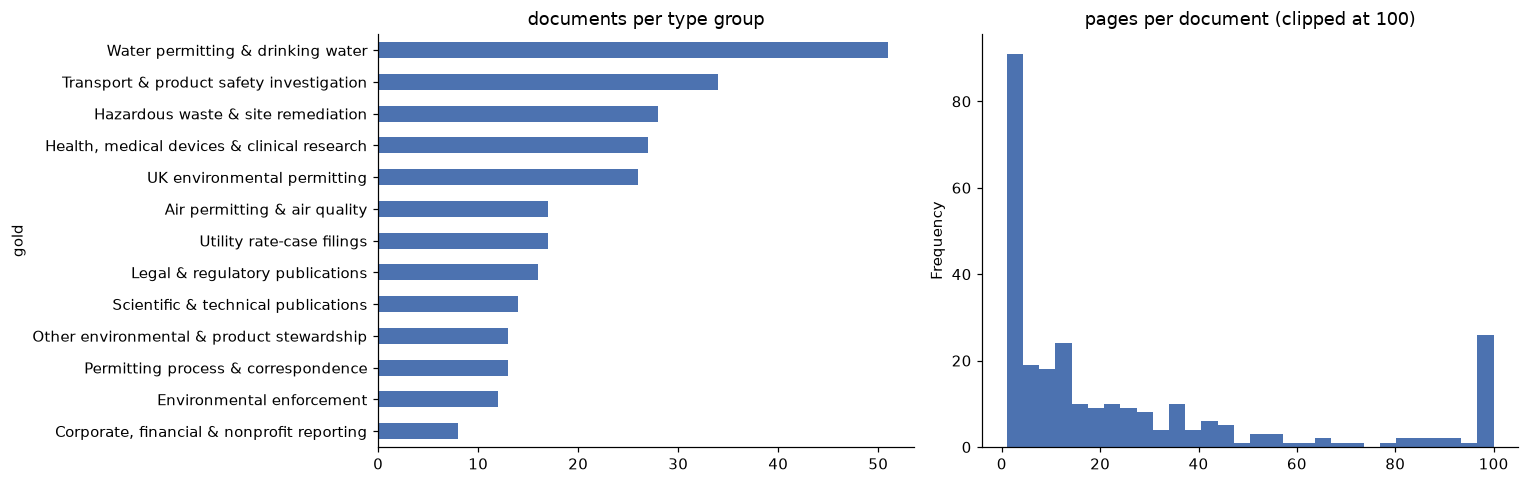

dataset,env-us-facility-bundles,env-uk-environment-agency,science-us-usgs,epa-npdes-nh,epa-npdes-ma,nydps-coned-25-e-0072,safety-uk-maib,safety-us-cbp-cross,health-us-fda-pma,law-us-federal-register,...,health-us-clinical-trials,health-us-fda-510k,safety-us-nhtsa-recalls,safety-uk-raib,safety-uk-aaib,epa-npdes-me,california-npdes,drinking-water-ccr,nydps-liberty-water-26-w-0358,cms-sd-2567
docs,82.0,26.0,14.0,13.0,12.0,11.0,10.0,8.0,8.0,8.0,...,8.0,8.0,8.0,8.0,8.0,7.0,6.0,6.0,6.0,3.0
types,35.0,9.0,7.0,3.0,2.0,11.0,2.0,1.0,1.0,1.0,...,2.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,6.0,1.0
median_pages,10.0,20.5,18.0,29.0,53.0,9.0,9.0,2.0,32.0,4.5,...,8.0,12.0,2.0,41.0,6.0,42.0,134.5,3.0,2.0,21.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
corpus.gold.map(GROUP_OF).value_counts().sort_values().plot.barh(ax=axes[0], color="#4C72B0", title="documents per type group")
corpus.pages.clip(upper=100).plot.hist(ax=axes[1], bins=30, color="#4C72B0", title="pages per document (clipped at 100)")
plt.tight_layout(); plt.show()
corpus.groupby("dataset").agg(docs=("id", "count"), types=("gold", "nunique"), median_pages=("pages", "median")).sort_values("docs", ascending=False).T

The left panel counts documents per type group. Water permitting and drinking water is the largest group (51 documents) and corporate, financial and nonprofit reporting the smallest (8). The right panel is a histogram of pages per document, with every document over 100 pages counted in the last bar. Lengths are very uneven: 91 documents have four pages or fewer, and 24 have 100 or more (the longest has 435). That spread is why the excerpt length matters. For a two-page recall notice 8,000 characters is the whole document; for a 134-page permit it is the cover letter and the first pages.

The table lists the 22 collections. The facility records are the largest and most varied (82 documents over 35 types), 12 collections hold a single type each, and in the two rate cases every document has a different type. Median length runs from 2 pages (recall notices, customs rulings, the Liberty Water filings) to 134.5 (California discharge orders). In plain words, with the way each correct type was set:

| Collection (catalog name) | Publisher | Documents | Types | How the correct type was set |
|---|---|---|---|---|
| `env-us-facility-bundles` | EPA, state agencies and courts: records on individual US facilities | 82 | 35 | First page read by hand |
| `env-uk-environment-agency` | UK Environment Agency, on GOV.UK | 26 | 9 | Publisher's attachment title or GOV.UK category |
| `science-us-usgs` | US Geological Survey | 14 | 7 | Publication-series code (fact sheet, open-file report, circular and so on) |
| `epa-npdes-nh`, `epa-npdes-ma` | EPA Region 1 discharge permits, New Hampshire and Massachusetts | 13 and 12 | 3 and 2 | Words in the file name ("draft", "mod", "fact sheet") |
| `nydps-coned-25-e-0072`, `nydps-liberty-water-26-w-0358` | New York Public Service Commission, two rate cases | 11 and 6 | 11 and 6 | The commission's filing category |
| `safety-uk-maib` | UK Marine Accident Investigation Branch | 10 | 2 | File name: safety bulletin or full report |
| `health-us-clinical-trials` | ClinicalTrials.gov study documents | 8 | 2 | File name: protocol with or without its statistical analysis plan |
| `epa-npdes-me` | Maine Department of Environmental Protection | 7 | 2 | Words in the file name |
| 12 single-type collections | EPA pesticide labels (8); NHTSA vehicle recalls (8); FDA 510(k) clearances (8) and premarket approval summaries (8); US customs rulings (8); Federal Register rules (8); UK air (8) and rail (8) accident reports; UK charity annual reports from the Kleister research dataset (8); Missouri drinking-water reports (6); California discharge orders (6); South Dakota nursing-home inspection forms (3) | 87 | 1 each | The collection: every file in it is that type |

In all, 160 documents are environmental (permits, enforcement, waste and clean-up records, UK environmental permitting, pesticide labels) and 116 come from other fields.

Of the 78 types present, 21 have a single document, 64 have between one and four, and 11 have eight or more.

### 2.5 Dates and what the model may have seen

The catalog records an estimated first-publication date for every document (`published`), with its basis (`published_basis`: a registry entry, a publisher listing, a date printed in the document, or an estimate from the content) and a confidence (`published_confidence`). The decision model's knowledge cutoff is not recorded in `data/`; [OpenAI's GPT-6 Luna model page](https://developers.openai.com/api/docs/models/gpt-6-luna) gives 18 May 2026 (checked 28 October 2026).

Against that date, 236 documents are dated before the cutoff, 35 after it (25 on a registry, publisher or in-document date, 10 on content estimates) and 5 carry only a year or month that spans it. The 35 later documents come mostly from the UK Environment Agency (16) and the Liberty Water rate case (6). One question on 8,000 characters got 31 of the 35 later documents right (89%) and 216 of the 236 earlier ones (92%). The later group is small and drawn mostly from two of the harder collections, so the split can neither confirm nor rule out an effect of memory. This notebook was built before the repository required data newer than the models, so all results use all 276 documents and are an upper bound for unseen documents.

## 3. Method

Every design gives the model the same evidence: the start of the document's extracted text, either the first 2,000 characters (about one page) or the first 8,000 (about two to four pages). The file name is not shown. Names such as `draft...permit.pdf` would give the answer away, and the test is whether the model can read the type from the content. Every type question uses one instruction: "What type of document is this? Choose the single best-matching document type. Judge by the document's form and purpose, not just its topic." Each answer option is a type name with its one-sentence description.

| Model | Pinned version | Provider and how it was called | Size and precision | Settings | Why included |
|---|---|---|---|---|---|
| GPT-6 Luna through OpenAI's Decisions API | Not recorded. The notebook called the undated name `openai/gpt-6-luna-decisions`, and the cached replies carry no dated version | OpenAI, through OpenRouter's Decisions endpoint | Not published | Choice questions; one instruction for every type question; probabilities in steps of 0.01 | The decision model whose ways of asking are compared |
| Llama Nemotron Embed VL 1B v2 | Not recorded. Free endpoint `nvidia/llama-nemotron-embed-vl-1b-v2:free` | NVIDIA, through OpenRouter's embeddings endpoint | About 1 billion parameters (from the name); precision not recorded | 512-number vectors | Builds the shortlist, and on its own is the similarity-only baseline |

### 3.1 Calls per document

One box per model call. All decision calls go to the same model, eight documents run at a time, and a refusal is not retried.

```mermaid
flowchart LR
    doc["Document text<br/>first 2,000 or 8,000 characters<br/>file name not shown"]
    subgraph B ["One question"]
        b["Decisions API (OpenRouter)<br/>1 choice question over all 101 types<br/>returns a probability per type"]
    end
    subgraph C ["Group first"]
        c1["Decisions API, call 1<br/>choice over 13 groups<br/>returns a probability per group"]
        c2["Decisions API, call 2<br/>choice over the types in the top 2 groups<br/>returns a probability per type"]
        c1 -->|"waits; passes the top 2 groups"| c2
    end
    subgraph D ["Shortlist first"]
        d1["Embedding model (OpenRouter, free)<br/>similarity to the 101 type descriptions"]
        d2["Decisions API<br/>choice over the 15 closest types<br/>returns a probability per type"]
        d1 -->|"top 15 types"| d2
    end
    out["Most probable type + its probability"]
    doc --> b
    doc --> c1
    doc --> d1
    b --> out
    c2 --> out
    d2 --> out
```

- Similarity only (code name A) picks the type whose description is closest to the document text, with no decision call.
- One question (B1 on 2,000 characters, B2 on 8,000) asks one choice question over all 101 types.
- Group first (C, the "cascade") asks which of the 13 groups fits, then asks for a type among the types of the two most probable groups. Its probability is the two groups' probability times the top type's probability.
- Shortlist first (D) takes the 15 types whose descriptions are closest to the document and asks one choice question over those.

Group first and shortlist first read 8,000 characters. Running one question at both lengths isolates the effect of reading more. What to look for under the code: the share of documents whose correct type is among the 15 closest types, which caps the shortlist design.

### 3.2 Worked example: a pesticide label, start to finish

The file `019713-00750-20260831.pdf` (catalog ID `label-019713-00750-20260831`) comes from EPA's pesticide label system. It has 94 pages. Its correct type, "Pesticide product label", comes from the collection: every file in it is a registered label.

The notebook extracts the first six pages and keeps 8,000 characters. The first page is EPA's registration notice, a form letter. The model's text begins:

```text
U.S. ENVIRONMENTAL PROTECTION AGENCY
Office of Pesticide Programs
Registration Division (7505T)
...
EPA Reg. Number: 19713-750
Date of Issuance: 8/31/26
NOTICE OF PESTICIDE:  X Registration
...
Name of Pesticide Product: Drexel Imitator® AG
```

The notice runs to about character 2,000, ending with the approving official's signature and "EPA Form 8570-6". The label comes after it. At character 3,945 the text reads "ACTIVE INGREDIENT: Glyphosate in the form of its isopropylamine salt ... 41.0%", followed by first aid and precautionary statements.

Each request holds the evidence (the text), one question with the instruction "What type of document is this? Choose the single best-matching document type. Judge by the document's form and purpose, not just its topic.", and the 101 types with their descriptions. The cached replies (read from `data/decisions_cache_classification.jsonl`):

| | One question, 2,000 characters | One question, 8,000 characters |
|---|---|---|
| Input tokens (a token is about four characters of English, the unit the service bills) | 3,623 | 4,903 |
| Cost of the call | $0.00036 | $0.00049 |
| Three most probable types | Regulatory correspondence letter 0.46; Permit decision document 0.22; Wastewater discharge permit (final) 0.04 | Pesticide product label 0.94; Regulatory correspondence letter 0.04; Draft or tentative discharge permit 0.01 |
| Scored | Wrong; correct type not in the top three | Right; probability 0.94 |

Most of each request is the list of 101 type descriptions, so four times as much document text adds only about a third to the tokens. Group first gave "Other environmental and product stewardship" 0.97 as the group and then "Pesticide product label" 1.00, for a combined probability of 0.98. Shortlist first gave the label 0.96 from a 15-type list that did not contain "Regulatory correspondence letter". On 2,000 characters the model saw only the notice, and a notice of registration is a letter in form. On 8,000 it also saw the label and chose it.

In [8]:
INSTR = ("What type of document is this? Choose the single best-matching document type. Judge by the document's "
         "form and purpose, not just its topic.")


def state_for(row, n_chars):
    return row["text"][:n_chars]


def ranked(probs, n=5):
    return sorted(probs, key=probs.get, reverse=True)[:n]


TYPES = labels.type.tolist()
docs = corpus.to_dict("records")

# A. embeddings
L = embed([DESC[t] for t in TYPES])
D = embed([state_for(r, LONG) for r in docs])
sim = D @ L.T
emb_rank = np.argsort(-sim, axis=1)
preds = {"A. embedding nearest-label": [{"top": [TYPES[j] for j in emb_rank[i, :5]], "conf": float(np.exp(sim[i].max() / 0.02) / np.exp(sim[i] / 0.02).sum()), "calls": []}
                                        for i in range(len(docs))]}


# B. flat: all 101 types in one question
def flat(row, n_chars):
    r = decide(state_for(row, n_chars), {"doc_type": {"type": "choice", "instructions": INSTR, "criteria": DESC}})
    p = r["answers"]["doc_type"]["probabilities"]
    return {"top": ranked(p), "conf": max(p.values()), "calls": [r]}


preds["B1. flat, first 2k chars"] = pmap(lambda r: flat(r, SHORT), docs)
preds["B2. flat, first 8k chars"] = pmap(lambda r: flat(r, LONG), docs)

# C. cascade: group → type (beam 2)
GROUP_DESC = {g: f"{g}. Types: " + "; ".join(t.rstrip(' †') for t in types) + "." for g, types in TAXONOMY.items()}


def cascade(row, beam=2):
    state = state_for(row, LONG)
    r1 = decide(state, {"group": {"type": "choice", "instructions": "Which family of documents does this document belong to?", "criteria": GROUP_DESC}})
    pg = r1["answers"]["group"]["probabilities"]
    keep = ranked(pg, beam)
    r2 = decide(state, {"doc_type": {"type": "choice", "instructions": INSTR, "criteria": {t: DESC[t] for t in TYPES if GROUP_OF[t] in keep}}})
    p = r2["answers"]["doc_type"]["probabilities"]
    return {"top": ranked(p), "conf": sum(pg[g] for g in keep) * max(p.values()), "calls": [r1, r2]}


preds["C. cascade group→type (beam 2)"] = pmap(cascade, docs)

# D. shortlist
K = 15


def shortlist(i):
    cand = [TYPES[j] for j in emb_rank[i, :K]]
    r = decide(state_for(docs[i], LONG), {"doc_type": {"type": "choice", "instructions": INSTR, "criteria": {t: DESC[t] for t in cand}}})
    p = r["answers"]["doc_type"]["probabilities"]
    return {"top": ranked(p), "conf": max(p.values()), "calls": [r]}


preds[f"D. embed top-{K} → decide"] = pmap(shortlist, range(len(docs)))
gold_pos = np.array([np.flatnonzero(emb_rank[i] == TYPES.index(d["gold"]))[0] for i, d in enumerate(docs)])
print("gold type inside the embedding shortlist: " + ", ".join(f"top-{k}: {(gold_pos < k).mean():.1%}" for k in (1, 5, 15, 30)))

gold type inside the embedding shortlist: top-1: 64.9%, top-5: 85.9%, top-15: 93.1%, top-30: 96.4%


The printed line says how often the similarity search puts the correct type near the top of its ranking. The correct type was the single closest for 64.9% of documents, among the closest 5 for 85.9%, among the closest 15 for 93.1% and among the closest 30 for 96.4%. The shortlist design uses the closest 15, so it can be right on at most 93.1% of documents (257 of 276), whatever the decision model does. Similarity alone is right exactly when the closest type is correct, so its accuracy will be the first number, 64.9%.

### 3.3 How answers are scored

Accuracy (also called top-1 accuracy) is the share of documents whose most probable type is the correct type. Higher is better. Top-3 accuracy counts a document as right when the correct type is among the three most probable; it shows how often a person picking from three suggestions would find the right one.

Accuracy rewards getting the common types right. Macro-F1 gives every type equal weight. For each type it combines two shares: of the documents the model called that type, how many really were (precision), and of the documents of that type, how many the model found (recall). F1 is their harmonic mean, and macro-F1 averages F1 over the 78 types present. A small example: ten documents, nine final permits and one modification, and a model that calls all ten "final permit". Accuracy is 9 of 10, or 90%. F1 for final permits is about 0.95 (precision 9/10, recall 9/9), F1 for modifications is 0, and macro-F1 is 0.47. A model that ignores rare types scores well on accuracy and poorly on macro-F1.

Group accuracy counts an answer as right when the chosen type is in the same group as the correct one. The probability of an answer is the model's probability for its top type. For group first it is the probability of the two kept groups multiplied by the top type's probability. For similarity only it is a score computed from the similarities, used only to rank answers. Cost per 1,000 documents comes from the `usage.cost` field of each cached reply, and time per document from its `latency_s` field. Intervals are 95% bootstrap intervals: the 276 documents are resampled with replacement 2,000 times and the middle 95% of the resulting accuracies is reported.

### 3.4 Unreadable replies

A decision model's reply is always a probability for each listed answer, so there is no free text that could break a format. The one way a request fails is a refusal: the service returns an error instead of probabilities. The notebook counts a refusal as a wrong answer and reports refusals in their own column. There was one, in the shortlist design, described in section 5.

## 4. Results

### 4.1 Which way of asking works best

The next cell scores the five runs on all 276 documents. Its rows use the code names: A is similarity only, B1 and B2 are one question on 2,000 and 8,000 characters, C is group first ("cascade") and D is shortlist first. The columns are accuracy (`acc@1`), top-3 accuracy (`acc@3`), macro-F1, group accuracy, accuracy on the 160 environmental and the 116 other documents, refusals, input tokens per document and cost per 1,000 documents. Green shading marks higher accuracy and macro-F1. Compare B2, C and D first: they read the same 8,000 characters and differ only in how the types are put to the model.

In [9]:
gold = corpus.gold.to_numpy()
rows, hits = [], {}
for name, P in preds.items():
    top1 = np.array([p["top"][0] for p in P])
    hits[name] = top1 == gold
    calls = [c for p in P for c in p["calls"]]
    rows.append({
        "method": name, "acc@1": hits[name].mean(), "acc@3": np.mean([g in p["top"][:3] for p, g in zip(P, gold)]),
        "macro-F1": f1_score(gold, top1, labels=sorted(set(gold)), average="macro", zero_division=0),
        "group acc": np.mean([GROUP_OF[t] == GROUP_OF[g] for t, g in zip(top1, gold)]),
        "acc (environmental)": hits[name][corpus.env].mean(), "acc (other)": hits[name][~corpus.env].mean(),
        "refused": sum(p.get("refused", False) for p in P),
        "input tok/doc": sum(c["usage"]["input_tokens"] for c in calls) / len(P),
        "$ / 1k docs": 1000 * sum(c["usage"]["cost"] for c in calls) / len(P),
    })
results = pd.DataFrame(rows).set_index("method")
results.style.format({c: "{:.1%}" for c in ["acc@1", "acc@3", "macro-F1", "group acc", "acc (environmental)", "acc (other)"]}
                     | {"input tok/doc": "{:,.0f}", "$ / 1k docs": "${:.2f}"}).background_gradient(subset=["acc@1", "macro-F1"], cmap="Greens")

,acc@1,acc@3,macro-F1,group acc,acc (environmental),acc (other),refused,input tok/doc,$ / 1k docs
method,,,,,,,,,
A. embedding nearest-label,64.9%,81.5%,50.9%,88.0%,60.6%,70.7%,0,0,$0.00
"B1. flat, first 2k chars",87.0%,93.1%,84.0%,92.4%,86.2%,87.9%,0,"3,640",$0.36
"B2. flat, first 8k chars",90.9%,96.0%,85.4%,96.7%,91.2%,90.5%,0,"4,748",$0.47
C. cascade group→type (beam 2),90.9%,95.3%,86.5%,96.4%,91.9%,89.7%,0,"4,720",$0.47
D. embed top-15 → decide,88.0%,92.0%,79.5%,94.6%,90.0%,85.3%,1,"2,174",$0.22


As counts out of 276: similarity only 179, one question on 2,000 characters 240, on 8,000 characters 251, group first 251 and shortlist first 243 (recounted from the cached replies).

One question on 8,000 characters and group first tie at 251 of 276 (90.9%). Group first has slightly higher macro-F1 (0.865 against 0.854) and the same cost per document, because its two shorter questions together carry about as many tokens as one long one. Matching the two runs document by document, both were right on 248, both wrong on 22, and each was right on 3 that the other missed. No result here separates them.

The shortlist is cheaper and less accurate. It sends less than half the tokens ($0.22 per 1,000 documents) and got 243 right (88.0%). On the 275 documents where it returned an answer it got 243 right (88.4%), so the refusal does not change the order. Document by document, one question on 8,000 characters was right on 15 documents the shortlist missed, and the shortlist on 7 that one question missed. An exact sign test on those 22 documents gives p = 0.13, so the gap of 3 points could be chance at this sample size.

The median time per document, from the cached `latency_s` field with eight documents at a time, was 1.8 seconds for one question at either length, 4.0 for group first (two calls in turn) and 0.8 for the shortlist, not counting its untimed embedding step.

Similarity alone is far behind at 179 of 276 (64.9%). It also chose a distractor type, one that never occurs in the corpus, 26 times, 16 of them "Discharge monitoring report". The four decision-model runs together chose a distractor twice in 1,103 answers, both times "Journal article / research paper".

The next cell draws accuracy with 95% bootstrap intervals. Each bar will be one run, labelled with its code name. Its length is accuracy on all 276 documents on a scale from 0 to 1 (the axis has no label; 0.9 means 90%), and the black line is the 95% bootstrap interval. The green circle is accuracy on the 160 environmental documents and the red square on the 116 from other fields. The title states the set-up rather than the finding.

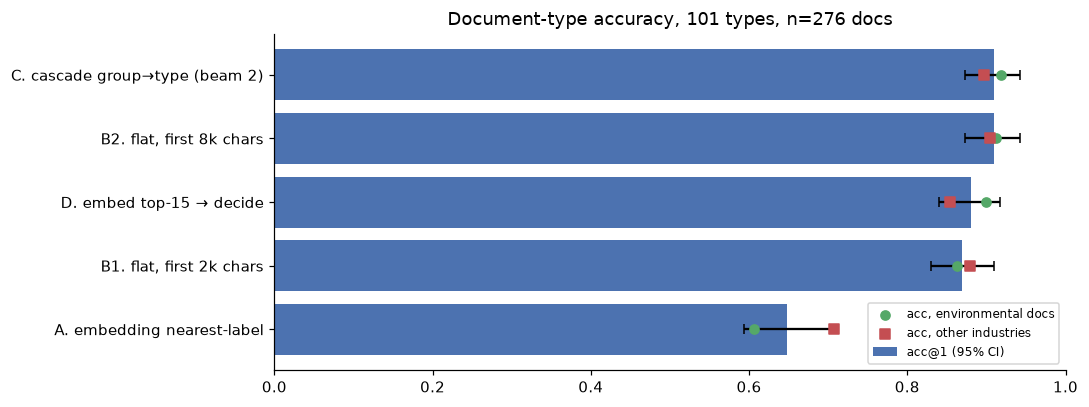

In [10]:
def bootstrap_ci(h, n=2000):
    rng = np.random.default_rng(0)
    return np.percentile(rng.choice(h, (n, len(h))).mean(axis=1), [2.5, 97.5])


r = results.sort_values("acc@1")
ci = np.array([bootstrap_ci(hits[m]) for m in r.index])
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(r.index, r["acc@1"], xerr=[r["acc@1"] - ci[:, 0], ci[:, 1] - r["acc@1"]], color="#4C72B0", capsize=3, label="acc@1 (95% CI)")
ax.scatter(r["acc (environmental)"], r.index, color="#55A868", zorder=3, label="acc, environmental docs")
ax.scatter(r["acc (other)"], r.index, color="#C44E52", marker="s", zorder=3, label="acc, other industries")
ax.set_xlim(0, 1); ax.legend(fontsize=8, loc="lower right"); ax.set_title(f"Document-type accuracy, {len(labels)} types, n={len(corpus)} docs")
plt.tight_layout(); plt.savefig(ROOT / "figures" / "accuracy_by_method.png", dpi=150, bbox_inches="tight"); plt.show()

The top three bars sit within 3 points of each other, and their intervals overlap: 87.3% to 94.2% for both one question on 8,000 characters and group first, 84.1% to 91.7% for the shortlist. Environmental documents were not harder for the decision model: one question on 8,000 characters got 146 of 160 environmental documents right (91.2%) and 105 of 116 others (90.5%). Similarity alone is the exception, at 60.6% against 70.7%.

Many documents do not separate the designs at all. In 11 collections, 85 documents in all, every decision-model run got every document right: the recall notices, customs rulings, accident reports, FDA documents, drinking-water reports, California and Massachusetts permits and the nursing-home forms. A typical one is `nhtsa-25v060-rcmn-25v060-2255`, a one-page General Motors bulletin of 553 characters headed "Safety Recall ... Chrome Grille Deflector May Detach". All four runs answered "Vehicle safety recall notice", with probabilities 1.00, 1.00, 0.92 and 0.99. The comparison between designs rests on the other 191 documents.

#### Why the shortlist loses some documents and wins others

The shortlist caps what the decision model can do: as section 3 showed, it held the correct type for 93.1% of documents (257 of 276). Of the shortlist design's 33 misses, 19 came from documents whose type was not on the list (one of these is also the refused request), and 14 were wrong choices from a list that included it.

The 19 missing types cluster where types differ by form within one subject: 6 of the 14 US Geological Survey documents, 5 of 26 UK Environment Agency documents, 5 of 82 facility records, 2 of 8 clinical-trial protocols and 1 Con Edison filing. `usgs-doc-usgs-fs20253054` is a four-page USGS fact sheet on undiscovered petroleum in the Haynesville Formation. Similarity ranked "Science fact sheet" 72nd of the 101 types; the closest were "Phase I environmental site assessment" and "Site map or figures". The shortlist design chose "Environmental research or evidence report" at 0.79. One question on 8,000 characters, which saw all 101 types, chose "Science fact sheet" at 0.99. This fits the idea that a similarity search sorts by subject rather than by form, though 19 documents are too few to establish it.

The shortlist also got 7 documents right that one question on 8,000 characters missed, and in 5 of them the type one question chose was not on the shortlist. It got all 8 pesticide labels right, against 5 for one question, and for none of the 8 did "Regulatory correspondence letter" make the shortlist, so the decision model could not give the tempting wrong answer. For `protocol-nct04688346` it chose "Clinical study protocol with statistical analysis plan" (0.91), but plain "Clinical study protocol" was not on its list, and no analysis-plan text appears in the first 8,000 characters (section 5). For `fr-doc-2025-05536` it chose "Federal Register rule" because "Federal Register notice" was not on its list. These are right answers for a reason that would not carry over to a different type list.

### 4.2 How much of each document to read

The next table gives accuracy per collection for every run, sorted by one question on 8,000 characters (column B2), coloured from red (0%) to green (100%). Compare columns B1 and B2: they differ only in how much text the model read. The first column is the number of documents in the collection, so a row of 6 documents moves in steps of about 17 points.

In [11]:
best = results["acc@1"].idxmax()
fam = corpus.assign(**{m.split(".")[0]: hits[m] for m in preds}).groupby("dataset")[[m.split(".")[0] for m in preds]].mean()
fam.insert(0, "docs", corpus.dataset.value_counts())
fam.sort_values(best.split(".")[0]).style.format({c: "{:.0%}" for c in fam.columns[1:]}).background_gradient(subset=fam.columns[1:], cmap="RdYlGn", vmin=0, vmax=1)

,docs,A,B1,B2,C,D
dataset,,,,,,
nydps-coned-25-e-0072,11,36%,55%,55%,64%,64%
epa-pesticide-labels,8,100%,0%,62%,50%,100%
health-us-clinical-trials,8,50%,62%,62%,62%,62%
env-uk-environment-agency,26,58%,81%,81%,88%,73%
nydps-liberty-water-26-w-0358,6,50%,83%,83%,67%,67%
epa-npdes-me,7,71%,43%,86%,86%,86%
kleister-charity-cohort,8,100%,88%,88%,88%,88%
law-us-federal-register,8,62%,75%,88%,75%,88%
epa-npdes-nh,13,54%,92%,92%,92%,92%


Reading 8,000 characters instead of 2,000 raised the one-question design from 240 to 251 right. The change fixed 11 documents and broke none of the 240 already right. An exact sign test on 11 against 0 gives p = 0.001. For 22 documents the extracted text is 2,000 characters or shorter, so the two runs saw the same text; 101 documents have less than 8,000 characters in all.

The same table as counts of correct documents:

| Collection | Documents | Similarity only | One question, 2,000 | One question, 8,000 | Group first | Shortlist first |
|---|---|---|---|---|---|---|
| `nydps-coned-25-e-0072` | 11 | 4 | 6 | 6 | 7 | 7 |
| `epa-pesticide-labels` | 8 | 8 | 0 | 5 | 4 | 8 |
| `health-us-clinical-trials` | 8 | 4 | 5 | 5 | 5 | 5 |
| `env-uk-environment-agency` | 26 | 15 | 21 | 21 | 23 | 19 |
| `nydps-liberty-water-26-w-0358` | 6 | 3 | 5 | 5 | 4 | 4 |
| `epa-npdes-me` | 7 | 5 | 3 | 6 | 6 | 6 |
| `kleister-charity-cohort` | 8 | 8 | 7 | 7 | 7 | 7 |
| `law-us-federal-register` | 8 | 5 | 6 | 7 | 6 | 7 |
| `epa-npdes-nh` | 13 | 7 | 12 | 12 | 12 | 12 |
| `env-us-facility-bundles` | 82 | 47 | 78 | 78 | 78 | 75 |
| `science-us-usgs` | 14 | 3 | 12 | 14 | 14 | 8 |
| 11 collections all right under every decision-model run | 85 | 70 | 85 | 85 | 85 | 85 |

Four collections changed between the two lengths. Pesticide labels went from 0 of 8 to 5 of 8, Maine permits from 3 of 7 to 6 of 7, USGS documents from 12 of 14 to 14 of 14 and Federal Register rules from 6 of 8 to 7 of 8. The pesticide labels open with EPA's registration notice and most Maine permits with a department letter. On the short excerpt the model filed all eight labels and three of the seven Maine permits as letters, sometimes with high probability. `me-permit-me0102581` opens with a Maine DEP letter, "Enclosed please find a copy of your final MEPDES permit and Maine WDL renewal". On 2,000 characters the model said "Regulatory correspondence letter" at 0.97; on 8,000 it said "Wastewater discharge permit (final)" at 1.00, which is correct.

The pattern is the one from the illustrative example. Where the first page states the type, a page is enough, and the extra text changed nothing in 18 of the 22 collections. Where the first page is a cover sheet, the extra pages are what the model needs, and it pays about a third more in tokens for every document to get them.

### 4.3 The most frequent confusions

For the errors of one question on 8,000 characters, the next cell counts each pair of correct type and chosen type and shows the 12 most frequent. The code calls this run `best`: one question on 8,000 characters and group first tie on accuracy, and the code takes the first of the two.

In [12]:
top1 = np.array([p["top"][0] for p in preds[best]])
conf_pairs = pd.Series([f"{g}  →  {t}" for g, t in zip(gold, top1) if g != t]).value_counts().head(12)
conf_pairs.rename("count").to_frame()

,count
Pesticide product label → Regulatory correspondence letter,3
Clinical study protocol with statistical analysis plan → Clinical study protocol,3
Agency corporate report → Environmental research or evidence report,2
Remedy statement of basis / proposed remedy → TSCA PCB storage/disposal approval,1
Site map or figures → Remediation progress / monitoring report,1
Environmental permit application or notification form → Hazardous waste (RCRA) permit,1
Compliance inspection report → Regulatory correspondence letter,1
Wastewater discharge permit (final) → Regulatory correspondence letter,1
Discharge permit modification → Wastewater discharge permit (final),1
Environmental permit (EPR) → Permit variation notice,1


The 25 errors form 20 distinct pairs, and only three occur more than once: pesticide labels filed as letters (3), protocols with an analysis plan filed as plain protocols (3) and agency corporate reports filed as research reports (2). Most pairs are neighbours: a document and its cover letter, the same document with or without one of its parts, or two report types from the same agency. Section 5 reads these documents.

### 4.4 Using the probability to choose what a person checks

The plan from the opening was to accept confident answers and send the rest to a person. The next cell tests that plan in two ways.

The plot ranks each run's answers from most to least probable. For each share of documents accepted (horizontal axis, "coverage") it shows the accuracy on those accepted (vertical axis). A useful probability gives a curve that starts high and falls only towards the right. Two things in this plot need care. Each curve starts at the tenth document. And many answers share the top probability of 1.00, so the order within that tie is the order of the documents in the corpus, not a ranking. The left part of every curve reflects that order: an error at 1.00 (`emerald-2013-final-statement-basis`, section 5) is among the first ten documents in every run, which is why all four curves start at 0.9. The legend cuts the group-first label off after "(b".

The table under the plot is for one question on 8,000 characters. For each threshold it gives the share of documents accepted, the accuracy on those, and the accuracy on the documents sent to a person.

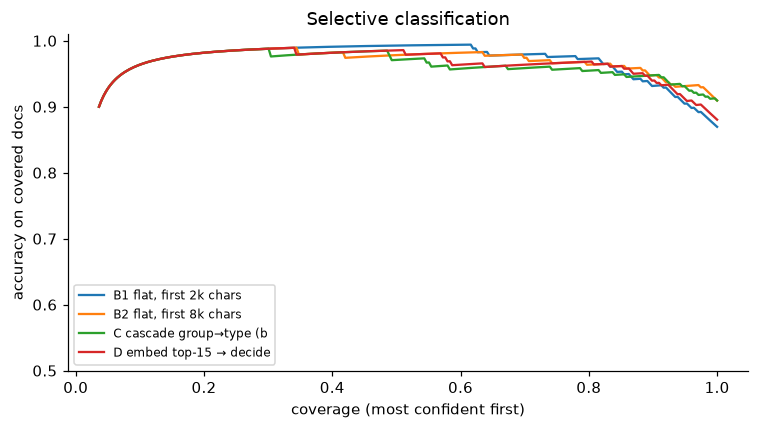

,auto-accept if conf ≥,coverage,accuracy on accepted,accuracy on rest
0,0.00,1.00,0.91,nan
1,0.50,0.99,0.92,0.00
2,0.70,0.96,0.93,0.36
3,0.90,0.93,0.93,0.60


In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
for m in preds:
    if m.startswith("A."):
        continue
    conf = np.array([p["conf"] for p in preds[m]]); h = hits[m]
    order = np.argsort(-conf, kind="stable"); cum = np.cumsum(h[order]) / np.arange(1, len(h) + 1)
    ax.plot((np.arange(1, len(h) + 1) / len(h))[9:], cum[9:], label=m.split(".")[0] + m.split(".")[1][:22])
ax.set_xlabel("coverage (most confident first)"); ax.set_ylabel("accuracy on covered docs"); ax.set_ylim(0.5, 1.01)
ax.legend(fontsize=8); ax.set_title("Selective classification")
plt.tight_layout(); plt.show()

conf = np.array([p["conf"] for p in preds[best]]); h = hits[best]
pd.DataFrame([{"auto-accept if conf ≥": t, "coverage": (conf >= t).mean(), "accuracy on accepted": h[conf >= t].mean(),
               "accuracy on rest": h[conf < t].mean() if (conf < t).any() else np.nan} for t in (0.0, 0.5, 0.7, 0.9)]
             ).style.format("{:.2f}").set_caption(f"Thresholds for: {best}")

The table as counts:

| Accept if probability is at least | Documents accepted | Right among accepted | Sent to a person | Right among those sent |
|---|---|---|---|---|
| 0 (accept all) | 276 | 251 (91%) | 0 | |
| 0.5 | 272 | 251 (92%) | 4 | 0 |
| 0.7 | 265 | 247 (93%) | 11 | 4 |
| 0.9 | 256 | 239 (93%) | 20 | 12 |

The threshold barely helps. At 0.9 a person checks 20 documents (7% of the folder) and finds 8 of the 25 errors among them, while 17 errors pass unchecked. Accuracy on the accepted documents rises only from 91% to 93%.

The reason shows in the probabilities themselves. The service returns them in steps of 0.01, and 214 of the 276 answers came back at exactly 1.00. Seven of those 214 were wrong, so the top of the scale cannot rank them any further. Among the 25 errors, 12 had a probability of 0.97 or more and only 4 were below 0.5. The model is usually right when it is sure, but when it is wrong it is usually just as sure.

The curves are shaped by the same ties. For one question on 8,000 characters, 214 answers (78% of documents) have probability 1.00, and 207 of them are right (96.7%); the other 62 documents hold 18 of the 25 errors. On 2,000 characters 189 answers are at 1.00 with 4 errors, group first has 166 at its top value with 7 errors, and the shortlist 179 with 7. The probability separates a confident block from the rest, but it cannot rank the answers inside that block, and every run has errors inside it. These tie counts were computed from the cached replies.

A different rule does better on this data. The model's most common wrong answer was "Regulatory correspondence letter": it gave that answer 9 times, and 5 of them were wrong. Checking every document called a letter means looking at 9 documents and finds 5 errors. Checking those plus everything under 0.9 means looking at 28 documents (10%) and finds 12 of the 25 errors. This rule was found by looking at these errors, so it needs testing on new documents before anyone relies on it. These counts were computed from the cached replies.

## 5. Error analysis

The next cell lists the wrong answers of one question on 8,000 characters, with the probability and the first words of the text the model saw, the 12 most confident first. All 12 have a probability of 0.97 or more; across all 25 errors, 17 have 0.9 or more. The `file` column is the file name from the web address, and three of these rows share the name `viewdoc.aspx`, so the discussion uses catalog IDs. The numbers at the left are positions in the list of errors, not stable IDs.

In [14]:
pd.DataFrame([{"dataset": d["dataset"], "file": fname(d)[:40], "gold": g, "predicted": p["top"][0], "conf": round(p["conf"], 2),
               "first words": re.sub(r"\s+", " ", d["text"][:110])}
              for d, g, p in zip(docs, gold, preds[best]) if p["top"][0] != g]).sort_values("conf", ascending=False).head(12)

,dataset,file,gold,predicted,conf,first words
0,env-us-facility-bundles,cad-050806850-chla-final-statement-of-ba,Remedy statement of basis / proposed remedy,TSCA PCB storage/disposal approval,1.00,Statement of Basis Approval for Commercial Storage and Disposal of Polychlorinated Bip...
5,epa-npdes-me,finalme0002054permitmod-2026.pdf,Discharge permit modification,Wastewater discharge permit (final),1.00,STATE OF MAINE DEPARTMENT OF ENVIRONMENTAL PROTECTION MELANIE LOYZIM COMMISSIONER JANE...
21,nydps-coned-25-e-0072,viewdoc.aspx,Tariff leaves,Rate case pre-filed testimony,1.00,BEFORE THE STATE OF NEW YORK PUBLIC SERVICE COMMISSION _______________________________...
14,health-us-clinical-trials,prot_sap_000.pdf,Clinical study protocol with statistical analysis plan,Clinical study protocol,1.00,1 Cardiovascular Effects of Racemic Epinephrine Pellets Used in Pediatric Restorative ...
24,kleister-charity-cohort,sha256e-s1615111--21d5a7a8640e60c3b0532f,Charity annual report and financial statements,Agency corporate report,1.00,Construction Industry Training Board (CITB) Annual Report and Accounts 2014 for the ye...
20,nydps-coned-25-e-0072,viewdoc.aspx,Rate case motion,Rate case correspondence,1.00,"Joshua A. Konecni Vice President Consolidated Edison Company of New York, Inc. 4 Irvin..."
11,env-uk-environment-agency,epr-bx1942ix-v004_milegate_extension_lan,Environmental permit (EPR),Permit variation notice,1.00,Variation and consolidation application number EPR/BX1942IX/V004 1 Notice of variation...
23,nydps-liberty-water-26-w-0358,viewdoc.aspx,Rate case motion,Protective order or confidentiality filing,0.99,"677 BROADWAY, SUITE 1101 ALBANY, NEW YORK 12207 518.427.9700 JEFFREY D. KUHN MEMBER DI..."
15,health-us-clinical-trials,prot_sap_000.pdf,Clinical study protocol with statistical analysis plan,Clinical study protocol,0.99,Evidence based education in thoracic ultrasound – A randomized controlled trial compar...
9,env-uk-environment-agency,evidence_base_for_the_reservoir_safety_r,Agency corporate report,Environmental research or evidence report,0.99,Date: August 2026 Reservoir Safety Research Strategy Evidence Base for the Reservoir S...


The 12 rows map to these catalog IDs, top to bottom:

| File (as shown) | Catalog ID |
|---|---|
| `cad-050806850-chla-final-statement-of-ba` | `emerald-2013-final-statement-basis` |
| `finalme0002054permitmod-2026.pdf` | `me-permit-me0002054` |
| `viewdoc.aspx` (tariff leaves) | `coned-25-e-0072-406da397-0000-c262-89e6-6ee27c5bd5a3` |
| `prot_sap_000.pdf` (cardiovascular effects) | `protocol-nct04688346` |
| `sha256e-s1615111--...` | `kc-047` |
| `viewdoc.aspx` (rate case motion) | `coned-25-e-0072-c0d0ae98-0000-ce42-8115-c9139cd27b98` |
| `epr-bx1942ix-v004_milegate_extension_lan` | `case-e09bc0640908-pdf-0` |
| `viewdoc.aspx` (Liberty Water motion) | `liberty-water-26-w-0358-f026759e-0000-c229-b4fa-39cc989b6942` |
| `prot_sap_000.pdf` (thoracic ultrasound) | `protocol-nct07846228` |
| `evidence_base_for_the_reservoir_safety_r` | `reservoir-safety-research-strategy-2026` |
| `089950-00001-20250506.pdf` | `label-089950-00001-20250506` |
| `schiller-station-ar-096.pdf` | `epa-schiller-ar-096` |

Read against their text, 18 of the 25 errors share one of three causes: the type is beyond the text the model received (6), the correct type is arguable (6), or the type comes from a rate-case filing category (6). The other 7 do not share a cause.

#### The type is beyond the text the model received

Three pesticide labels were still filed as letters on 8,000 characters. In `label-089950-00001-20250506` the label's ingredient statement appears at character 5,831 ("ACTIVE INGREDIENTS: Hydrogen peroxide ... 6.98%"), after a long registration notice with conditions, and the model still chose the letter at 0.98. In `label-000524-00670-20260309` none of the usual label headings (directions for use, first aid, precautionary statements, storage and disposal) appears in the first 8,000 characters; "active ingredients" appears once, at character 6,926, inside the notice's conditions. The model chose the letter at 0.38. In `label-100368-00006-20250814` the readable text ends at character 4,208 with "Enclosure: Product Label". The text after it is unreadable, from a font the text extractor could not decode: 13% of the excerpt's characters are control characters, and no label heading appears. Given the text it received, the model's answer (letter, 0.92) is a fair reading. That error belongs to the extraction step, and no choice of design would fix it.

Three of the four clinical-trial protocols filed with an analysis plan were called plain protocols. Their correct type comes from the file name `prot_sap_000.pdf`, which ClinicalTrials.gov uses for a protocol filed together with its statistical analysis plan. In `protocol-nct04688346` the phrase "statistical analysis" does not appear in the first 8,000 characters at all. In the other two it appears at characters 4,387 and 6,662, and the model still chose the plain protocol (0.92 and 0.99). A document that contains a protocol and, later, an analysis plan looks like a protocol for as long as the excerpt lasts.

#### The correct type is arguable

`emerald-2013-final-statement-basis` was filed by hand as "Remedy statement of basis / proposed remedy". Its first words are "Statement of Basis / Approval for Commercial Storage and Disposal of Polychlorinated Biphenyls (PCBs)", issued by EPA Region 9. Every decision-model run chose "TSCA PCB storage/disposal approval" at 1.00. The two descriptions both fit: the first covers a regulator's document explaining "a proposed cleanup remedy or permit/approval decision", and the second an "EPA approval (proposed or final) to commercially store or dispose of polychlorinated biphenyls". It is a statement of basis for a PCB approval.

`me-permit-me0002054` has the correct type "Discharge permit modification" because its file name, `finalme0002054permitmod-2026.pdf`, contains "mod". The cover letter says it encloses "your final MEPDES permit and Maine WDL renewal", and the permit's page 3 lists "MODIFICATIONS REQUESTED". Every run chose the final permit (1.00 on 8,000 characters). The document is a renewal that includes a modification.

Four more errors look similar. `kc-047` is the Construction Industry Training Board's "Annual Report and Accounts 2014", "Presented to Parliament". It sits in the charity collection, so its correct type is a charity annual report, but the board is a public body, and every decision-model run called it an agency corporate report. `fr-doc-2025-05536` is printed in the Federal Register's "Rules and Regulations" section, so the collection rule calls it a rule, but its text says "ACTION: Notification of enforcement of regulation", and the model called it a notice (0.94). `epa-schiller-ar-096` is a one-page letter from New Hampshire's environment department following up an inspection. The type "Compliance inspection report" is described as a "report or follow-up letter documenting a regulatory compliance inspection", and every run chose the letter (0.97 on one question). `reservoir-safety-research-strategy-2026`, filed under GOV.UK's corporate report category, is headed "Evidence Base for the Reservoir Safety Research Strategy", and the model called it a research or evidence report (0.99).

In these 6 of the 25 errors, the document's own words support the model's answer about as well as the recorded type. A second reviewer might change some of these labels, which would move accuracy by up to 6 documents (2.2 points). It would not change the order of the designs, because every decision-model run made all six of these errors except the Federal Register notice, which the shortlist got right.

#### Neighbouring types told apart by a filing category

The rate-case filings are the hardest collection, at 6 of 11 for Con Edison and 5 of 6 for Liberty Water. Their correct types come from the category the commission filed them under, and several documents look like a different category. `coned-25-e-0072-c0d0ae98-0000-ce42-8115-c9139cd27b98`, filed as a motion, is a letter from a Con Edison vice president to the Secretary of the Commission; the model called it correspondence at 1.00. `coned-25-e-0072-406da397-0000-c262-89e6-6ee27c5bd5a3`, filed as tariff leaves, opens with the case caption "BEFORE THE STATE OF NEW YORK PUBLIC SERVICE COMMISSION", as testimony does, and the model called it pre-filed testimony at 1.00. All 17 rate-case filings share the file name `viewdoc.aspx`, which is why the examples use catalog IDs.

#### The one refusal

The shortlist request for `wild-mooring-anglian-waterways` came back with HTTP 502 and the message "OpenAI refused to answer question "doc_type"". The document is the Environment Agency's terms and conditions for a non-residential wild mooring licence, and nothing in its first 8,000 characters suggests a reason to refuse. The same text was answered in the other designs: one question chose "Environmental permit (EPR)" at 0.29, and group first chose the correct "Regulatory guidance document" (type probability 0.49). The code treats a refusal as final, so the request was not retried.

#### What these examples cannot show

They show which type the model returned for which text, not why. The pattern that the excerpt's first pages decide the answer is consistent across the pesticide labels, the Maine permits and the protocols, but it rests on 19 documents in three collections.

## 6. Cost of the run

The next cell adds up the cost recorded in every cached Decisions reply, including replies the final run does not use.

In [15]:
spent = sum(v["usage"]["cost"] for v in decision_cache.data.values() if "usage" in v)
print(f"Decisions API spend recorded in this notebook's cache: ${spent:.2f} over {len(decision_cache.data)} calls")

Decisions API spend recorded in this notebook's cache: $0.47 over 1634 calls


The cache holds 1,634 replies with a recorded cost of $0.47. Not all of them belong to the run above. The final run makes 1,379 calls: 276 for each length of one question, 552 for group first and 275 answered shortlist calls. Those are 1,357 distinct requests, because for the 22 documents with 2,000 characters of text or fewer both lengths send the same request, and they cost $0.41. The other $0.06 is 275 shortlist requests whose 15-type lists match none of the final shortlists, left in the cache from an earlier shortlist. Two cached replies are refusals: the one in section 5 and one among those older requests. The embedding endpoint is free, and its cache holds 377 vectors (101 type descriptions and 276 documents). These splits were counted by matching the cache against the replayed run, and [`data/PROTOCOL.md`](data/PROTOCOL.md) records them. The run date is not recorded in `data/`; the notebook and its caches were added to this repository on 17 October 2026.

## 7. What the evidence supports

- For a type list that fits in one question, ask one question over all the types and give the model about 8,000 characters. Group first matched its accuracy at the same cost per document, but it takes two calls and more than twice as long (median 4.0 against 1.8 seconds).
- Use a shortlist only when its savings matter more than accuracy. It halves the cost here, but the decision model can never be more accurate than the shortlist allows (93.1% of documents had their type on it), and its misses fall where types share a subject. Most of its wins came from leaving out a tempting wrong answer, which a team could do on purpose with a rule for a known collection.
- Do not use the probability alone to choose what a person checks: 17 of 25 errors had 0.9 or more. Checking documents by the type they were given (here, every document called a letter) found more errors per document read, but that rule needs testing on new documents.
- Check the text extraction before blaming the classifier. One label was unreadable after its cover letter, and 13 scanned PDFs had no text at all.

The uncertainty that most needs another experiment is the cover-letter problem: whether showing the model the page images, or the first page of each attachment, would fix documents such as the pesticide labels, at the same cost.

## 8. Limitations

- Older public data. 236 of 276 documents were public before the model's knowledge cutoff of 18 May 2026, so the accuracy is an upper bound for new documents. The 35 later documents (31 right) are too few, from too few collections, to measure an effect of memory.
- Few documents per type. The 276 documents cover 78 types, 64 of them with one to four documents. Macro-F1 and every per-type or per-collection rate are noisy.
- Correct types. For 82 documents a single reviewer, not named in the notebook, set the type from the first page, with no second reviewer. The rules for the other 194 inherit the publishers' filing choices. Section 5 found 6 errors where the recorded type is arguable.
- One model, one instruction, one reply per request. Each request was sent once and cached, so the notebook does not measure how much the answers vary between calls. The model version was not pinned.
- Text only. The model never saw page layout, 13 scanned PDFs were dropped and one label was garbled by text extraction, so a real folder with scans would score lower.
- Analysis history. The comparison was not fixed before the results were seen, and the cache holds requests from an earlier shortlist (section 6). [`data/PROTOCOL.md`](data/PROTOCOL.md) records what is known of the run.

## 9. How to reproduce

| File in `data/` | What it holds |
|---|---|
| `catalog/<collection>/files.jsonl` | One row per public file: web address, sha256, size, licence, publisher, estimated publication date with its basis and confidence |
| `decisions_cache_classification.jsonl` | Every Decisions API reply, keyed by a hash of the full request: probabilities per answer, token usage, cost and time |
| `embeddings_cache.npz` | The 377 embedding vectors, keyed by a hash of the model name and text |
| `PROTOCOL.md` | What is known of the run's history and settings |

The cache stores replies but not request text, so the per-document examples in this notebook's text were recovered by repeating the notebook's selection and text extraction on the downloaded PDFs and looking up each request's key in the cache. Every request matched. Running the notebook replays everything from these files without model calls:

```bash
jupyter nbconvert --to notebook --execute --inplace 03_document_type_classification.ipynb
```

The first run downloads about 300 MB of PDFs into `data/docs/` (git-ignored) and checks each against its sha256. A request missing from the cache needs `OPENROUTER_API_KEY`. The README beside this notebook tells the same story without code.

## 10. Future work and further reading

### Future work

- Show the page as well as the text. The Decisions API also accepts images. Add the first page image, or the first page of each attachment, and check whether layout fixes the cover-letter and protocol-with-plan confusions in section 5 (motivated by the pesticide labels, 5 of 8 on 8,000 characters).
- Read the right part of the document. Reading 8,000 instead of 2,000 characters fixed 11 documents. Test the first 4,000 plus the last 2,000 characters, or the start of each attachment, at the same token budget.
- Test review rules on new documents. Compare a probability threshold with "check every document given a type that is often wrong" at the same number of documents checked, on a fresh set (motivated by 17 of 25 errors at 0.9 or more).
- Bring back the 13 scanned PDFs with OCR (optical character recognition) and report them separately, since scanned documents are common in regulatory records.
- Collect at least 10 documents per type, all published after the model's cutoff, with a second reviewer for hand-set types so that the correct types have an agreement rate (motivated by 64 of 78 types having one to four documents).

### Further reading

Links checked on 17 October 2026.

- [Evaluation of Deep Convolutional Nets for Document Image Classification and Retrieval](https://arxiv.org/abs/1502.07058) (Harley et al., 2015). Introduced RVL-CDIP, the standard document-type benchmark, built from page images rather than text.
- [LayoutLMv3: Pre-training for Document AI with Unified Text and Image Masking](https://arxiv.org/abs/2204.08387) (Huang et al., 2022). One model over text and page image together, the layout signal that sending the page image would add.
- [DiT: Self-supervised Pre-training for Document Image Transformer](https://arxiv.org/abs/2203.02378) (Li et al., 2022). Classifies documents from the image alone, a baseline without a language model for types that differ in form.
- [Kleister: Key Information Extraction Datasets Involving Long Documents with Complex Layouts](https://arxiv.org/abs/2105.05796) (Stanisławek et al., 2021). The source of the UK charity annual reports in this corpus (`kleister-charity-cohort`), released as an extraction benchmark for long documents.
- [Decisions](https://developers.openai.com/api/docs/guides/decisions) (OpenAI API guide). The vendor's description of the API tested here: typed questions over fixed options, answered with probabilities instead of text.